# Practical 1 — When should we reduce the dimension? PCA-Net for viscous Burgers

## Central question

A PDE field sampled on $n_x$ grid points is an $n_x$-dimensional vector. But does the physics really explore all these degrees of freedom?

We will answer four questions:

1. **Why might this phenomenon be low-dimensional?**
2. **How can PCA expose and exploit that structure?**
3. **What do we gain by learning in the latent space?**
4. **When does the idea stop working?**

The final goal is not to conclude that PCA-Net is always better. It is to learn how to decide when a reduced model is a sensible prior.

### Learning objectives

By the end of the practical, you should be able to:

- distinguish spatial Fourier energy from PCA explained variance;
- use a spectrum to motivate — but not prove — reducibility;
- choose a PCA rank from reconstruction error rather than habit;
- build the operator $u_0\mapsto u(T)$ in latent coordinates;
- separate **representation error** from **learning error**;
- compare PCA-Net with a full-field MLP and the numerical solver;
- explain why smooth fields can remain easy to compress as the grid is refined;
- identify a case where a fixed linear subspace becomes inefficient.

### Suggested timing

| Part | Time |
|---|---:|
| 1. Read the phenomenon from the data | 15 min |
| 2. Discover low-dimensional structure | 20 min |
| 3. PCA-Net | 25 min |
| 4. What did compression buy us? | 20 min |
| 5. Resolution and limitation experiments | 20–30 min |
| Final synthesis | 10 min |

## 1 — Start from the phenomenon, not from the network

We consider the periodic viscous Burgers equation

$$
\partial_t u + u\,\partial_x u = \nu\,\partial_{xx}u,
\qquad x\in[0,2\pi],
$$

and learn the map

$$
\mathcal G_T:u_0(\cdot)\longmapsto u(\cdot,T).
$$

The nonlinear transport term can steepen a profile, while viscosity damps small spatial scales. Before choosing a machine-learning architecture, we first inspect what family of fields the PDE actually produces.

In [1]:
import copy
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 12
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


### Dataset — provided numerical solver

The initial conditions are smooth random Fourier series using only the first five frequencies. The PDE is solved with a Fourier pseudospectral method and RK4 time stepping.

You do **not** need to modify the solver. It represents the expensive numerical map that the surrogate will try to approximate repeatedly.

In [2]:
LENGTH = 2.0 * np.pi
NX = 128
VISCOSITY = 0.08
FINAL_TIME = 0.40


def sample_smooth_initial_conditions(n_samples, nx=NX, seed=0):
    rng = np.random.default_rng(seed)
    x = np.linspace(0.0, LENGTH, nx, endpoint=False)
    u0 = np.zeros((n_samples, nx), dtype=np.float64)

    for k in range(1, 6):
        a = rng.normal(size=(n_samples, 1)) / k**2
        b = rng.normal(size=(n_samples, 1)) / k**2
        u0 += a * np.sin(k * x)[None, :] + b * np.cos(k * x)[None, :]

    u0 -= u0.mean(axis=1, keepdims=True)
    maximum = np.maximum(np.max(np.abs(u0), axis=1, keepdims=True), 1e-8)
    target_amplitude = rng.uniform(0.65, 1.15, size=(n_samples, 1))
    u0 *= target_amplitude / maximum
    return x, u0.astype(np.float32)


def solve_viscous_burgers(u0, nu=VISCOSITY, final_time=FINAL_TIME,
                          dt_max=5e-3, return_trajectory=False, n_frames=5):
    u = np.asarray(u0, dtype=np.float64).copy()
    nx = u.shape[-1]
    wave_number = np.fft.fftfreq(nx, d=1.0 / nx)
    cutoff = nx // 3
    n_steps = int(np.ceil(final_time / dt_max))
    dt = final_time / n_steps
    saved_steps = set(np.linspace(0, n_steps, n_frames, dtype=int))
    frames = [u.copy()] if return_trajectory else None

    def rhs(v):
        v_hat = np.fft.fft(v, axis=-1)
        flux_hat = np.fft.fft(0.5 * v**2, axis=-1)
        flux_hat[..., np.abs(wave_number) > cutoff] = 0.0
        return np.fft.ifft(
            -1j * wave_number * flux_hat
            - nu * wave_number**2 * v_hat,
            axis=-1,
        ).real

    for step in range(1, n_steps + 1):
        k1 = rhs(u)
        k2 = rhs(u + 0.5 * dt * k1)
        k3 = rhs(u + 0.5 * dt * k2)
        k4 = rhs(u + dt * k3)
        u += dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0
        if return_trajectory and step in saved_steps:
            frames.append(u.copy())

    result = u.astype(np.float32)
    if return_trajectory:
        return result, np.stack(frames).astype(np.float32)
    return result


N_TRAIN, N_VAL, N_TEST = 800, 100, 150
N_TOTAL = N_TRAIN + N_VAL + N_TEST

x_grid, u0_all = sample_smooth_initial_conditions(N_TOTAL, seed=SEED)
uT_all = solve_viscous_burgers(u0_all)

u0_train = u0_all[:N_TRAIN]
uT_train = uT_all[:N_TRAIN]
u0_val = u0_all[N_TRAIN:N_TRAIN + N_VAL]
uT_val = uT_all[N_TRAIN:N_TRAIN + N_VAL]
u0_test = u0_all[-N_TEST:]
uT_test = uT_all[-N_TEST:]

print("Train:", u0_train.shape, "->", uT_train.shape)
print("Validation:", u0_val.shape, "Test:", u0_test.shape)

Train: (800, 128) -> (800, 128)
Validation: (100, 128) Test: (150, 128)


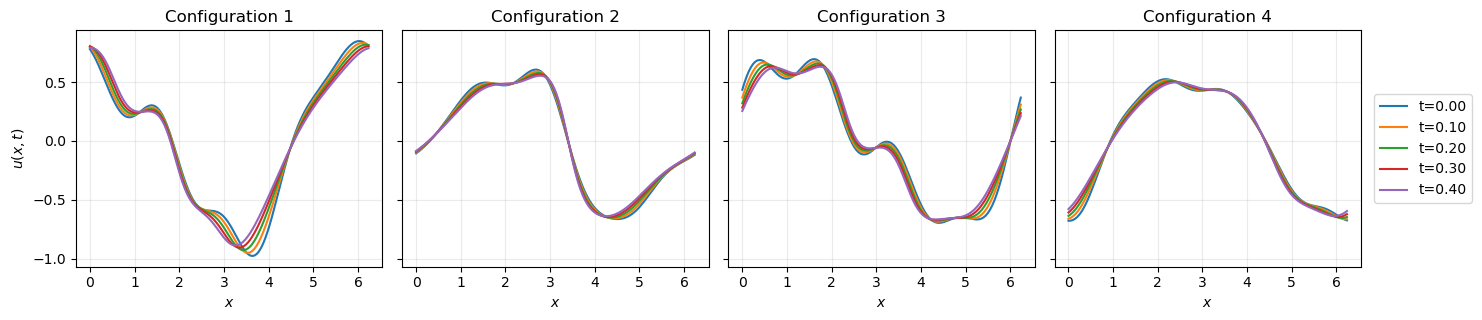

In [3]:
_, trajectories = solve_viscous_burgers(
    u0_all[:4], return_trajectory=True, n_frames=5
)
times = np.linspace(0.0, FINAL_TIME, trajectories.shape[0])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
for sample, ax in enumerate(axes):
    for frame, t in zip(trajectories[:, sample], times):
        ax.plot(x_grid, frame, label=f"t={t:.2f}")
    ax.set_title(f"Configuration {sample + 1}")
    ax.set_xlabel("$x$")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("$u(x,t)$")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

### Questions — read the physics first

1. Which part of the equation tends to create sharper gradients? Which part removes them?
2. Do the solutions look as if every grid point evolves independently?
3. If the grid were refined from 128 to 256 points **without adding new physical scales**, would you expect twice as many independent degrees of freedom?
4. What observation would make you skeptical of a low-dimensional representation?

## 2 — Is the phenomenon spectrally simple?

A first clue comes from the spatial Fourier spectrum. For each field we compute $|\hat u_k|^2$ and average over the dataset.

This is a **physical frequency spectrum**: it tells us which spatial scales are active. It is not yet PCA.

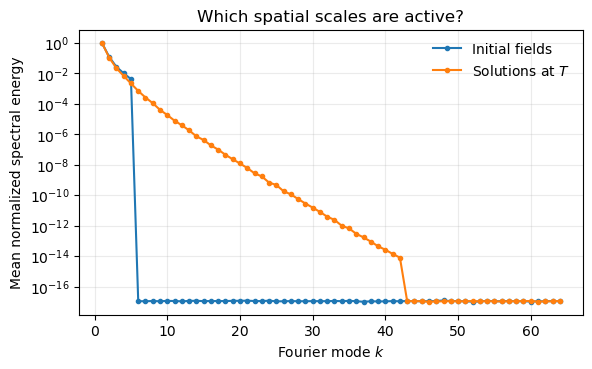

In [4]:
def mean_fourier_energy(fields):
    spectrum = np.fft.rfft(fields, axis=-1)
    return np.mean(np.abs(spectrum)**2, axis=0)

k = np.fft.rfftfreq(NX, d=1.0/NX)
energy_u0 = mean_fourier_energy(u0_train)
energy_uT = mean_fourier_energy(uT_train)

# Normalize only for visualization.
energy_u0 /= energy_u0.max()
energy_uT /= energy_uT.max()

fig, ax = plt.subplots(figsize=(6.5, 3.7))
ax.semilogy(k[1:], energy_u0[1:], "o-", ms=3, label="Initial fields")
ax.semilogy(k[1:], energy_uT[1:], "o-", ms=3, label="Solutions at $T$")
ax.set_xlabel("Fourier mode $k$")
ax.set_ylabel("Mean normalized spectral energy")
ax.set_title("Which spatial scales are active?")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()

### Questions — what does the Fourier spectrum tell us?

1. Why are the input frequencies concentrated at small $k$?
2. The Burgers nonlinearity can create frequencies absent from $u_0$. Why do the high-$k$ modes nevertheless remain weak here?
3. Does a rapidly decaying Fourier spectrum **prove** that the dataset lies in a low-dimensional linear subspace?

## 3 — Recall PCA: compress the dataset, not the physics equation

For snapshots stored as rows of a matrix $X$, PCA finds orthogonal directions $\phi_k$ that explain the variance of the dataset.

A rank-$r$ reconstruction is

$$
u(x) \approx \bar u(x) + \sum_{k=1}^{r} z_k\phi_k(x).
$$

The fraction of dataset variance captured by the first $r$ modes is

$$
E_r = \sum_{k=1}^{r}\frac{\sigma_k^2}{\sum_j \sigma_j^2}.
$$

**Important:** this "PCA energy" is statistical explained variance. It is different from the physical kinetic energy and from the Fourier spectrum above.

### Exercise — fit the PCA models

Use `sklearn.decomposition.PCA` to fit one PCA on the initial conditions and one on the final solutions. We first keep all available components so that we can inspect the spectrum before choosing a rank.

Only four lines are missing.

In [5]:
# TODO: create and fit a full PCA for inputs and outputs.
pca_input_full = None
pca_output_full = None

# Example syntax:
# pca = PCA().fit(training_snapshots)

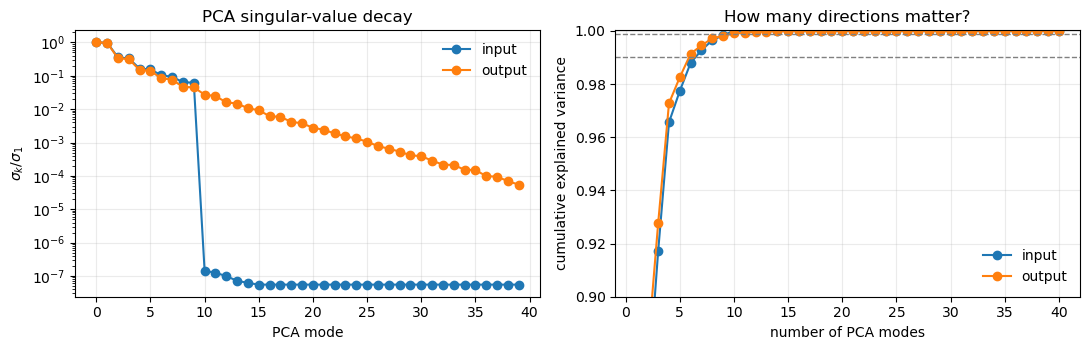

99.0000% variance -> input rank  7, output rank  6
99.9000% variance -> input rank 10, output rank 10
99.9900% variance -> input rank 10, output rank 15


In [7]:
def cumulative_variance(pca):
    return np.cumsum(pca.explained_variance_ratio_)

cum_in = cumulative_variance(pca_input_full)
cum_out = cumulative_variance(pca_output_full)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(pca_input_full.singular_values_[:40] / pca_input_full.singular_values_[0],
                 "o-", label="input")
axes[0].semilogy(pca_output_full.singular_values_[:40] / pca_output_full.singular_values_[0],
                 "o-", label="output")
axes[0].set(xlabel="PCA mode", ylabel="$\\sigma_k/\\sigma_1$", title="PCA singular-value decay")
axes[0].grid(alpha=0.25); axes[0].legend(frameon=False)

axes[1].plot(np.arange(1, 41), cum_in[:40], "o-", label="input")
axes[1].plot(np.arange(1, 41), cum_out[:40], "o-", label="output")
for level in [0.99, 0.999]:
    axes[1].axhline(level, color="0.5", linestyle="--", linewidth=1)
axes[1].set(xlabel="number of PCA modes", ylabel="cumulative explained variance", title="How many directions matter?")
axes[1].set_ylim(0.9, 1.0002)
axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

for threshold in [0.99, 0.999, 0.9999]:
    r_in = np.searchsorted(cum_in, threshold) + 1
    r_out = np.searchsorted(cum_out, threshold) + 1
    print(f"{threshold:7.4%} variance -> input rank {r_in:2d}, output rank {r_out:2d}")

### Questions — decide whether compression is justified

1. Why is the input PCA rank strongly limited here?
2. Why can the output require more PCA modes than the input even though viscosity smooths the field?
3. Is "99% explained variance" equivalent to "1% relative error" for every sample?
4. Based on the spectrum, would a rank around 10–15 look defensible for this dataset?

## 4 — Choose the rank from the reconstruction floor

Before training any network, ask a crucial question:

> **If the latent coefficients were predicted perfectly, how accurate could the final field possibly be?**

That accuracy floor is determined entirely by the PCA representation.

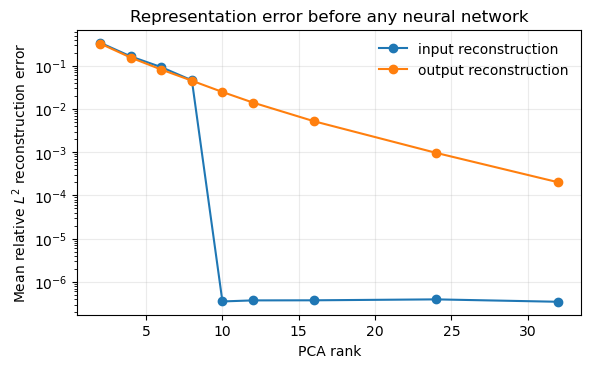

In [8]:
def relative_l2(prediction, truth):
    prediction = np.asarray(prediction)
    truth = np.asarray(truth)
    num = np.linalg.norm(prediction - truth, axis=-1)
    den = np.maximum(np.linalg.norm(truth, axis=-1), 1e-12)
    return num / den

ranks = [2, 4, 6, 8, 10, 12, 16, 24, 32]
input_floor = []
output_floor = []

for rank in ranks:
    p_in = PCA(n_components=rank).fit(u0_train)
    p_out = PCA(n_components=rank).fit(uT_train)
    rec_in = p_in.inverse_transform(p_in.transform(u0_test))
    rec_out = p_out.inverse_transform(p_out.transform(uT_test))
    input_floor.append(relative_l2(rec_in, u0_test).mean())
    output_floor.append(relative_l2(rec_out, uT_test).mean())

fig, ax = plt.subplots(figsize=(6.5, 3.7))
ax.semilogy(ranks, input_floor, "o-", label="input reconstruction")
ax.semilogy(ranks, output_floor, "o-", label="output reconstruction")
ax.set_xlabel("PCA rank")
ax.set_ylabel("Mean relative $L^2$ reconstruction error")
ax.set_title("Representation error before any neural network")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()

### Exercise — choose a working representation

We will use

```python
RANK_INPUT = 10
RANK_OUTPUT = 12
```

1. Is the output reconstruction floor small compared with the accuracy you expect from a surrogate?
2. What would be the consequence of choosing `RANK_OUTPUT = 4`?
3. What is the cost of choosing an unnecessarily large rank?

In [9]:
RANK_INPUT = 10
RANK_OUTPUT = 12

pca_input = PCA(n_components=RANK_INPUT).fit(u0_train)
pca_output = PCA(n_components=RANK_OUTPUT).fit(uT_train)

z0_train = pca_input.transform(u0_train).astype(np.float32)
z0_val = pca_input.transform(u0_val).astype(np.float32)
z0_test = pca_input.transform(u0_test).astype(np.float32)

zT_train = pca_output.transform(uT_train).astype(np.float32)
zT_val = pca_output.transform(uT_val).astype(np.float32)
zT_test = pca_output.transform(uT_test).astype(np.float32)

# Normalize INPUT latent variables only, to make optimization easier.
# We keep output PCA coefficients in their natural scale: because PCA modes
# are orthonormal, coefficient MSE then matches the MSE inside the PCA subspace.
z0_scale = np.maximum(z0_train.std(axis=0, keepdims=True), 1e-6)
z0_train_n = z0_train / z0_scale
z0_val_n = z0_val / z0_scale
z0_test_n = z0_test / z0_scale

uT_projection = pca_output.inverse_transform(zT_test)
print("Mean output PCA floor:", f"{relative_l2(uT_projection, uT_test).mean():.3%}")

Mean output PCA floor: 1.408%


## 5 — PCA-Net: learn only the map between reduced coordinates

The operator is approximated as

$$
u_0(x)
\xrightarrow{\text{PCA}}
z_0
\xrightarrow{\text{small MLP}}
\widehat z_T
\xrightarrow{\text{PCA}^{-1}}
\widehat u(x,T).
$$

The neural network therefore never sees a 128-dimensional output. It learns only a map

$$
\mathbb R^{10}\longrightarrow\mathbb R^{12}.
$$

### Exercise — complete the small latent network

Only complete the network definition and the forward pass. The training loop is provided.

In [10]:
class LatentMLP(nn.Module):
    def __init__(self, rank_in, rank_out, width=64):
        super().__init__()
        # TODO: define a small MLP rank_in -> width -> width -> rank_out.
        self.net = None

    def forward(self, z):
        # TODO
        pass

epoch   1 | train 2.647e+00 | val 2.567e+00
epoch  50 | train 7.768e-03 | val 1.024e-02
epoch 100 | train 3.606e-03 | val 5.362e-03
epoch 150 | train 2.103e-03 | val 3.694e-03
epoch 200 | train 1.440e-03 | val 2.746e-03
epoch 250 | train 1.057e-03 | val 2.270e-03
epoch 300 | train 8.307e-04 | val 1.910e-03
epoch 350 | train 6.702e-04 | val 1.733e-03
epoch 400 | train 5.618e-04 | val 1.480e-03
epoch 450 | train 4.831e-04 | val 1.313e-03
epoch 500 | train 4.370e-04 | val 1.147e-03
epoch 550 | train 4.018e-04 | val 1.036e-03
epoch 600 | train 3.315e-04 | val 1.022e-03
epoch 650 | train 3.275e-04 | val 9.232e-04
epoch 700 | train 2.895e-04 | val 8.491e-04
epoch 750 | train 2.932e-04 | val 7.439e-04
epoch 800 | train 2.726e-04 | val 7.213e-04
epoch 850 | train 2.552e-04 | val 6.446e-04
epoch 900 | train 2.513e-04 | val 6.357e-04
epoch 950 | train 2.050e-04 | val 5.821e-04
epoch 1000 | train 2.196e-04 | val 6.254e-04
Trainable latent-network parameters: 5,644


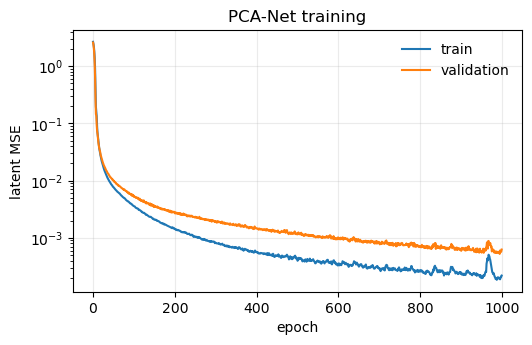

In [13]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_regressor(model, x_train, y_train, x_val, y_val,
                    epochs=1000, batch_size=128, lr=2e-3, verbose=True):
    x_train_t = torch.tensor(x_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    x_val_t = torch.tensor(x_val, dtype=torch.float32, device=device)
    y_val_t = torch.tensor(y_val, dtype=torch.float32, device=device)

    loader = DataLoader(TensorDataset(x_train_t, y_train_t),
                        batch_size=batch_size, shuffle=True)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train": [], "validation": []}
    best_state, best_val = None, float("inf")

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val_t), y_val_t).item()

        history["train"].append(running / len(x_train_t))
        history["validation"].append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

        if verbose and (epoch == 0 or (epoch + 1) % 50 == 0):
            print(f"epoch {epoch+1:3d} | train {history['train'][-1]:.3e} | val {val_loss:.3e}")

    model.load_state_dict(best_state)
    return model, history


latent_model = LatentMLP(RANK_INPUT, RANK_OUTPUT, width=64)
latent_model, history_pca = train_regressor(
    latent_model, z0_train_n, zT_train, z0_val_n, zT_val
)

print(f"Trainable latent-network parameters: {count_parameters(latent_model):,}")

fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.semilogy(history_pca["train"], label="train")
ax.semilogy(history_pca["validation"], label="validation")
ax.set(xlabel="epoch", ylabel="latent MSE", title="PCA-Net training")
ax.grid(alpha=0.25); ax.legend(frameon=False)
plt.show()

In [14]:
def predict_latent_model(model, z_input):
    model.eval()
    with torch.no_grad():
        z = torch.tensor(z_input, dtype=torch.float32, device=device)
        return model(z).cpu().numpy()

zT_pred = predict_latent_model(latent_model, z0_test_n)
uT_pred_pca = pca_output.inverse_transform(zT_pred)

err_pca_net = relative_l2(uT_pred_pca, uT_test)
err_pca_floor = relative_l2(uT_projection, uT_test)

print(f"PCA reconstruction floor : {err_pca_floor.mean():.3%}")
print(f"PCA-Net mean relative L2 : {err_pca_net.mean():.3%}")

PCA reconstruction floor : 1.408%
PCA-Net mean relative L2 : 1.948%


## 6 — Separate representation error from learning error

Every PCA-Net prediction belongs to the selected output PCA subspace. If $P_r u$ denotes the exact PCA projection, then orthogonality gives

$$
\|u-\widehat u\|_2^2
=
\underbrace{\|u-P_r u\|_2^2}_{\text{representation / truncation}}
+
\underbrace{\|P_r u-\widehat u\|_2^2}_{\text{latent prediction}}.
$$

Training can only reduce the second term.

### Exercise — quantify the two error sources

Complete the three MSE quantities and check the decomposition.

In [15]:
# TODO: fill these three quantities.
total_mse = None
pca_floor_mse = None
latent_prediction_mse = None

# print("decomposition residual =", abs(total_mse - pca_floor_mse - latent_prediction_mse))

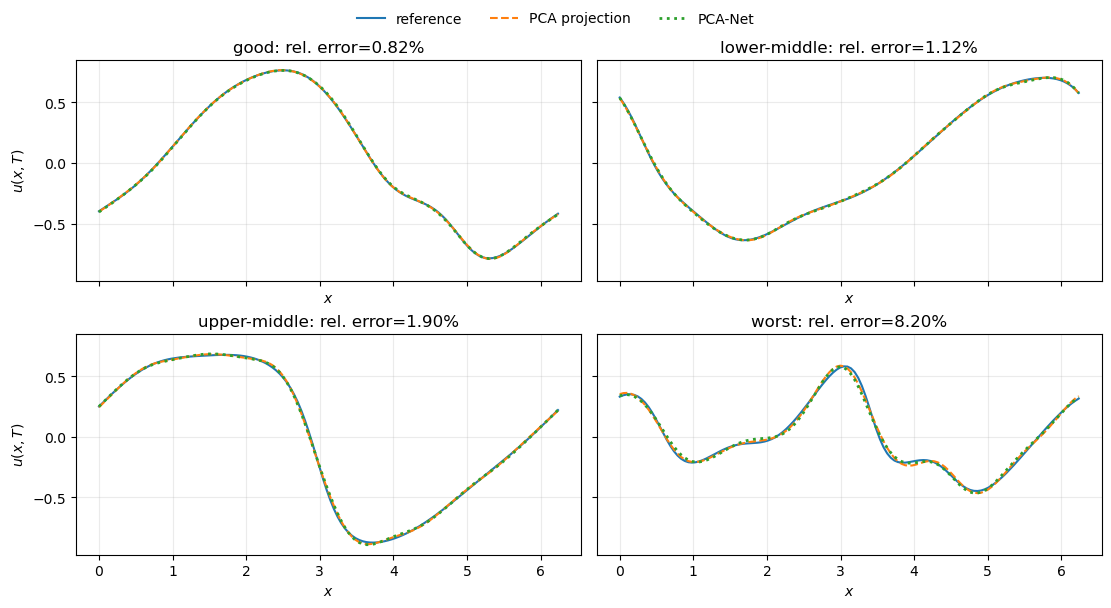

In [17]:
order = np.argsort(err_pca_net)
indices = [order[len(order)//10], order[len(order)//3], order[2*len(order)//3], order[-1]]
labels = ["good", "lower-middle", "upper-middle", "worst"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True, constrained_layout=True)
for ax, idx, label in zip(axes.ravel(), indices, labels):
    ax.plot(x_grid, uT_test[idx], label="reference")
    ax.plot(x_grid, uT_projection[idx], "--", label="PCA projection")
    ax.plot(x_grid, uT_pred_pca[idx], ":", linewidth=2, label="PCA-Net")
    ax.set_title(f"{label}: rel. error={err_pca_net[idx]:.2%}")
    ax.set_xlabel("$x$")
    ax.grid(alpha=0.25)
axes[0,0].set_ylabel("$u(x,T)$")
axes[1,0].set_ylabel("$u(x,T)$")
handles, labels_ = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="outside upper center", ncol=3, frameon=False)
plt.show()

### Questions — diagnose the model instead of looking only at one error number

1. If the PCA projection and the PCA-Net prediction are almost identical but both miss the reference, what should you change first: the MLP or the PCA rank?
2. If the PCA floor is tiny but PCA-Net is inaccurate, where is the bottleneck?
3. Why is the PCA floor a useful diagnostic before spending time tuning the neural network?

## 7 — What did dimensionality reduction buy us?

To make the trade-off concrete, compare PCA-Net with a conventional MLP that maps the full discretized field directly:

$$
\mathbb R^{128}\rightarrow\mathbb R^{128}.
$$

This is not meant to prove that one architecture is universally superior. We hold the problem deliberately simple and compare **representation size, parameter count, accuracy and online cost**.

In [19]:
class FullFieldMLP(nn.Module):
    def __init__(self, nx, width=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(nx, width),
            nn.SiLU(),
            nn.Linear(width, width),
            nn.SiLU(),
            nn.Linear(width, nx),
        )

    def forward(self, x):
        return self.net(x)


full_model = FullFieldMLP(NX, width=128)
full_model, history_full = train_regressor(
    full_model, u0_train, uT_train, u0_val, uT_val,
    epochs=1000, batch_size=128, lr=2e-3
)

with torch.no_grad():
    uT_pred_full = full_model(
        torch.tensor(u0_test, dtype=torch.float32, device=device)
    ).cpu().numpy()

err_full = relative_l2(uT_pred_full, uT_test)

print(f"Full-field MLP parameters: {count_parameters(full_model):,}")
print(f"PCA-Net latent parameters: {count_parameters(latent_model):,}")
print(f"Full-field MLP mean relative L2: {err_full.mean():.3%}")
print(f"PCA-Net mean relative L2       : {err_pca_net.mean():.3%}")

epoch   1 | train 2.085e-01 | val 8.361e-02
epoch  50 | train 8.482e-04 | val 9.945e-04
epoch 100 | train 3.576e-04 | val 4.753e-04
epoch 150 | train 2.457e-04 | val 3.238e-04
epoch 200 | train 1.675e-04 | val 2.401e-04
epoch 250 | train 1.372e-04 | val 2.105e-04
epoch 300 | train 1.194e-04 | val 1.685e-04
epoch 350 | train 1.067e-04 | val 1.736e-04
epoch 400 | train 8.801e-05 | val 1.500e-04
epoch 450 | train 9.865e-05 | val 1.493e-04
epoch 500 | train 6.732e-05 | val 1.268e-04
epoch 550 | train 1.892e-04 | val 3.737e-04
epoch 600 | train 5.583e-05 | val 1.148e-04
epoch 650 | train 6.354e-05 | val 1.233e-04
epoch 700 | train 5.235e-05 | val 1.129e-04
epoch 750 | train 7.750e-05 | val 1.555e-04
epoch 800 | train 8.494e-05 | val 1.145e-04
epoch 850 | train 5.500e-05 | val 1.276e-04
epoch 900 | train 4.041e-05 | val 9.289e-05
epoch 950 | train 3.428e-05 | val 7.445e-05
epoch 1000 | train 5.255e-05 | val 9.025e-05
Full-field MLP parameters: 49,536
PCA-Net latent parameters: 5,644
Full-fie

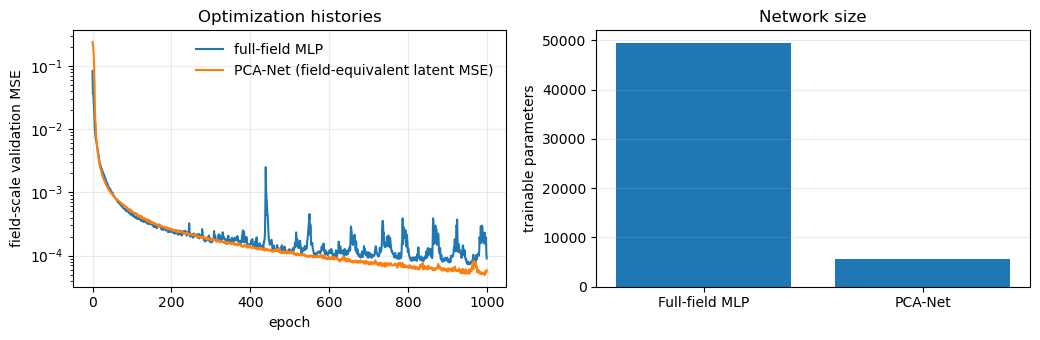

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
axes[0].semilogy(history_full["validation"], label="full-field MLP")
axes[0].semilogy(np.asarray(history_pca["validation"]) * RANK_OUTPUT / NX,
                    label="PCA-Net (field-equivalent latent MSE)")
axes[0].set(xlabel="epoch", ylabel="field-scale validation MSE", title="Optimization histories")
axes[0].grid(alpha=0.25); axes[0].legend(frameon=False)

axes[1].bar(["Full-field MLP", "PCA-Net"],
            [count_parameters(full_model), count_parameters(latent_model)])
axes[1].set_ylabel("trainable parameters")
axes[1].set_title("Network size")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### Online timing — surrogate versus numerical solve

The exact numbers are hardware-dependent, so interpret them only as orders of magnitude. The important distinction is:

- the numerical method solves the PDE again for every new input;
- a trained surrogate performs only algebraic operations;
- PCA-Net adds encode/decode operations but uses a much smaller learned map.

In [21]:
def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


def median_time(fn, repeats=8):
    fn()  # warm-up
    synchronize()
    values = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        synchronize()
        values.append(time.perf_counter() - start)
    return float(np.median(values))


def pcanet_pipeline():
    z = pca_input.transform(u0_test).astype(np.float32) / z0_scale
    z_pred = predict_latent_model(latent_model, z)
    return pca_output.inverse_transform(z_pred)


def full_pipeline():
    full_model.eval()
    with torch.no_grad():
        x = torch.tensor(u0_test, dtype=torch.float32, device=device)
        return full_model(x)

pca_time = median_time(pcanet_pipeline) / len(u0_test)
full_time = median_time(full_pipeline) / len(u0_test)

# Solver timing on a smaller batch: this is still a vectorized throughput measurement.
solver_subset = u0_test[:40]
start = time.perf_counter()
_ = solve_viscous_burgers(solver_subset)
solver_time = (time.perf_counter() - start) / len(solver_subset)

print(f"Median online time / sample")
print(f"  numerical solver : {1e3*solver_time:8.3f} ms")
print(f"  full-field MLP    : {1e3*full_time:8.3f} ms")
print(f"  PCA-Net pipeline  : {1e3*pca_time:8.3f} ms")

Median online time / sample
  numerical solver :    0.665 ms
  full-field MLP    :    0.002 ms
  PCA-Net pipeline  :    0.005 ms


### Questions — speed is not the only criterion

1. Why can PCA-Net have far fewer trainable parameters even though it still reconstructs a 128-point field?
2. Is the numerical solver comparison entirely fair?
3. When would the offline cost of generating training data make a surrogate unattractive?

## 8 — Does a finer grid necessarily make PCA-Net harder?

We now sample the **same already-computed continuous-looking trajectories** on grids of 32, 64 and 128 points.

For each grid we refit PCA and retrain a small latent model using the same ranks. This deliberately tests **stability of the reduced description across discretizations**.

> This is **not** zero-shot resolution invariance: the PCA basis and network are refit at each resolution.

,nx,error,floor,latent_params,full_mlp_params
0,32,0.059527,0.014080,5644,24864
1,64,0.059073,0.014081,5644,33088
2,128,0.060594,0.014081,5644,49536


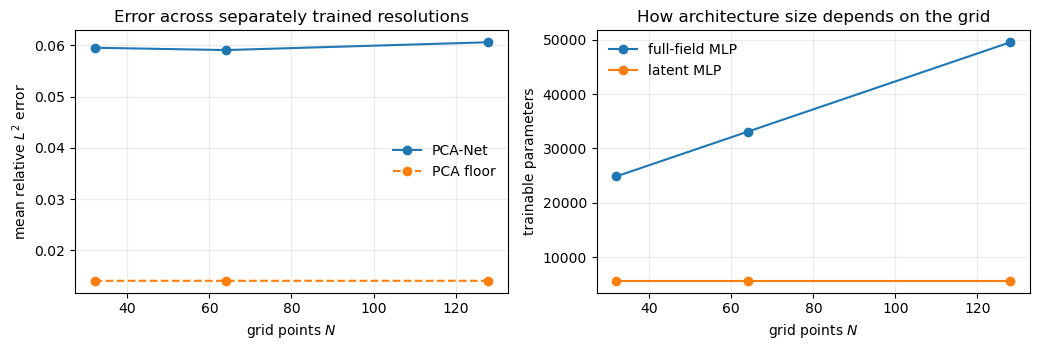

In [22]:
def train_pcanet_at_resolution(nx, epochs=45):
    stride = NX // nx
    u0_tr = u0_train[:, ::stride]
    uT_tr = uT_train[:, ::stride]
    u0_va = u0_val[:, ::stride]
    uT_va = uT_val[:, ::stride]
    u0_te = u0_test[:, ::stride]
    uT_te = uT_test[:, ::stride]

    p_in = PCA(n_components=RANK_INPUT).fit(u0_tr)
    p_out = PCA(n_components=RANK_OUTPUT).fit(uT_tr)

    z0_tr = p_in.transform(u0_tr).astype(np.float32)
    z0_va = p_in.transform(u0_va).astype(np.float32)
    z0_te = p_in.transform(u0_te).astype(np.float32)
    scale = np.maximum(z0_tr.std(axis=0, keepdims=True), 1e-6)

    zT_tr = p_out.transform(uT_tr).astype(np.float32)
    zT_va = p_out.transform(uT_va).astype(np.float32)

    torch.manual_seed(SEED)
    model = LatentMLP(RANK_INPUT, RANK_OUTPUT, width=64)
    model, _ = train_regressor(
        model, z0_tr/scale, zT_tr, z0_va/scale, zT_va,
        epochs=epochs, verbose=False
    )

    z_pred = predict_latent_model(model, z0_te/scale)
    pred = p_out.inverse_transform(z_pred)
    projection = p_out.inverse_transform(p_out.transform(uT_te))
    return {
        "nx": nx,
        "error": relative_l2(pred, uT_te).mean(),
        "floor": relative_l2(projection, uT_te).mean(),
        "latent_params": count_parameters(model),
        "full_mlp_params": count_parameters(FullFieldMLP(nx, width=128)),
    }

resolution_results = [train_pcanet_at_resolution(nx) for nx in [32, 64, 128]]
resolution_df = pd.DataFrame(resolution_results)
display(resolution_df)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].plot(resolution_df["nx"], resolution_df["error"], "o-", label="PCA-Net")
axes[0].plot(resolution_df["nx"], resolution_df["floor"], "o--", label="PCA floor")
axes[0].set(xlabel="grid points $N$", ylabel="mean relative $L^2$ error", title="Error across separately trained resolutions")
axes[0].grid(alpha=0.25); axes[0].legend(frameon=False)

axes[1].plot(resolution_df["nx"], resolution_df["full_mlp_params"], "o-", label="full-field MLP")
axes[1].plot(resolution_df["nx"], resolution_df["latent_params"], "o-", label="latent MLP")
axes[1].set(xlabel="grid points $N$", ylabel="trainable parameters", title="How architecture size depends on the grid")
axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### Questions — interpret the resolution experiment carefully

1. Why can PCA-Net error remain approximately stable while $N$ increases?
2. Did we prove that PCA-Net is resolution invariant?
3. Why does the latent MLP parameter count stay constant while the full-field MLP grows?
4. Give one situation where increasing $N$ **would** reveal genuinely new information and a fixed low rank could fail.

## 9 — Limitation: a low-dimensional nonlinear family may not be linearly reducible

PCA is a **linear** reduction. A particularly important failure mode is a sharp structure that moves through the domain.

We now consider inviscid Burgers after shock formation. The initial family depends only on amplitude and phase, but the output contains translated sharp fronts.

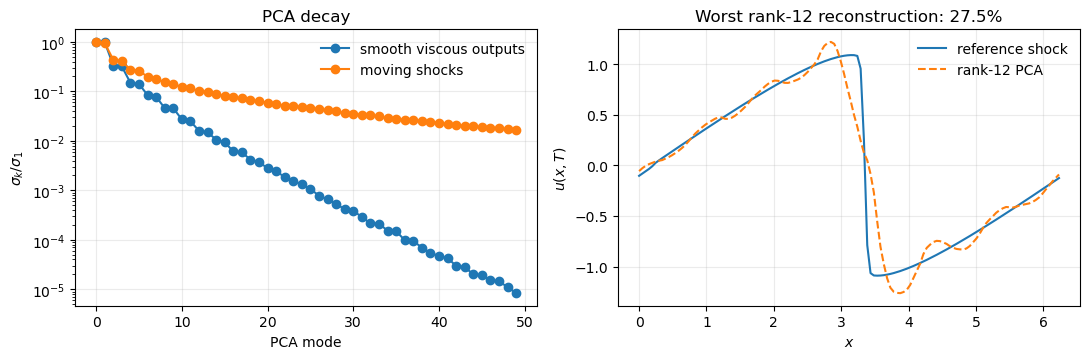

Mean rank-12 shock reconstruction error: 18.96%


In [23]:
def sample_shifted_sines(n_samples, nx=NX, seed=30):
    rng = np.random.default_rng(seed)
    x = np.linspace(0.0, LENGTH, nx, endpoint=False)
    amplitude = rng.uniform(0.85, 1.15, size=(n_samples, 1))
    phase = rng.uniform(0.0, LENGTH, size=(n_samples, 1))
    return x, (amplitude * np.sin(x[None, :] - phase)).astype(np.float32)


def solve_inviscid_burgers_rusanov(u0, final_time=1.3, cfl=0.35):
    u = np.asarray(u0, dtype=np.float64).copy()
    dx = LENGTH / u.shape[-1]
    t = 0.0
    while t < final_time - 1e-14:
        dt = min(cfl * dx / max(np.max(np.abs(u)), 1e-8), final_time - t)
        u_right = np.roll(u, -1, axis=-1)
        flux_right = (
            0.25 * (u**2 + u_right**2)
            - 0.5 * np.maximum(np.abs(u), np.abs(u_right)) * (u_right - u)
        )
        u -= (dt / dx) * (flux_right - np.roll(flux_right, 1, axis=-1))
        t += dt
    return u.astype(np.float32)

x_shock, shock_u0 = sample_shifted_sines(300, seed=30)
shock_uT = solve_inviscid_burgers_rusanov(shock_u0)

shock_train = shock_uT[:220]
shock_test = shock_uT[220:]
pca_shock_full = PCA().fit(shock_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].semilogy(pca_output_full.singular_values_[:50] / pca_output_full.singular_values_[0],
                 "o-", label="smooth viscous outputs")
axes[0].semilogy(pca_shock_full.singular_values_[:50] / pca_shock_full.singular_values_[0],
                 "o-", label="moving shocks")
axes[0].set(xlabel="PCA mode", ylabel="$\\sigma_k/\\sigma_1$", title="PCA decay")
axes[0].grid(alpha=0.25); axes[0].legend(frameon=False)

rank_bad = 12
pca_shock_12 = PCA(n_components=rank_bad).fit(shock_train)
shock_rec = pca_shock_12.inverse_transform(pca_shock_12.transform(shock_test))
shock_err = relative_l2(shock_rec, shock_test)
idx = int(np.argmax(shock_err))
axes[1].plot(x_shock, shock_test[idx], label="reference shock")
axes[1].plot(x_shock, shock_rec[idx], "--", label=f"rank-{rank_bad} PCA")
axes[1].set(xlabel="$x$", ylabel="$u(x,T)$", title=f"Worst rank-{rank_bad} reconstruction: {shock_err[idx]:.1%}")
axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

print("Mean rank-12 shock reconstruction error:", f"{shock_err.mean():.2%}")

### Questions — why does PCA struggle here?

1. The initial family is controlled by very few parameters. Why can its **output** nevertheless have a slowly decaying PCA spectrum?
2. Why is translating a sharp front difficult for a fixed global linear basis?
3. Would increasing the PCA rank help? What would be lost?
4. Suggest one alternative to "just increase the rank".

## 10 — Final comparison: when is dimensionality reduction useful?

First collect the quantitative observations from this run. Timing is machine-dependent; accuracy and parameter counts are more reproducible.

In [24]:
summary_numeric = pd.DataFrame({
    "method": ["Numerical solver", "Full-field MLP", "PCA-Net"],
    "trainable_parameters": [0, count_parameters(full_model), count_parameters(latent_model)],
    "mean_relative_L2": [0.0, float(err_full.mean()), float(err_pca_net.mean())],
    "online_ms_per_sample": [1e3*solver_time, 1e3*full_time, 1e3*pca_time],
})
display(summary_numeric)

,method,trainable_parameters,mean_relative_L2,online_ms_per_sample
0,Numerical solver,0,0.000000,0.664679
1,Full-field MLP,49536,0.014345,0.001512
2,PCA-Net,5644,0.019478,0.005079


### Final exercise — complete the reasoning table

Use the experiments above, not intuition alone.

| Method | Representation | Raw accuracy | Online cost | What happens when grid $N$ changes? | Main strength | Main limitation |
|---|---|---|---|---|---|---|
| Numerical solver |  |  |  |  |  |  |
| Full-field MLP |  |  |  |  |  |  |
| PCA-Net |  |  |  |  |  |  |

Then answer:

1. Give **three conditions** under which you would seriously consider PCA-Net.
2. Give **two warning signs** that should make you test another representation.
3. Why is "the field has 1000 grid points" not, by itself, an argument against a small latent model?
4. Why does this practical naturally motivate the Neural Operator practical that follows?

## Take-home message

Dimensionality reduction should not be the first reflex or the last resort. It should be a **testable modelling hypothesis**:

1. inspect the phenomenon and its active scales;
2. measure the data spectrum and reconstruction floor;
3. compress only if a small representation preserves the information you need;
4. separate representation error from learning error;
5. check whether the reduced space remains valid when the regime or resolution changes.

$$
\boxed{\text{Use PCA-Net when the data are linearly compressible — not simply because the vectors are large.}}
$$